In [29]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)
from google.colab import files

In [30]:
# Loading Data Set
df = pd.read_csv("heart.csv")
print("Shape: ", df.shape)
df

Shape:  (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [31]:
# Dataset Info:

print("DATA TYPES: ")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

#Dropping Duplicate Rows
df = df.drop_duplicates()
print("\nDuplicate rows:", df.duplicated().sum())

print("\nMISSING VALUES: ")
print(df.isnull().sum())

print("\nSTATISTICS: ")
df.describe()

DATA TYPES: 
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Duplicate rows: 723
Unique rows: 302

Duplicate rows: 0

MISSING VALUES: 
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

STATISTICS: 


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


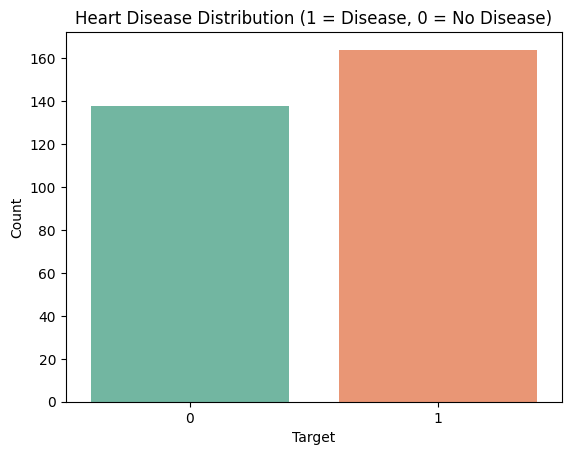


target
1    164
0    138
Name: count, dtype: int64


In [32]:
# TARGET VARIABLE DISTRIBUTION
# Where 1 means heart disease present, 0 means absent

sns.countplot(x = 'target', data = df, hue = 'target', palette = 'Set2', legend = False)
plt.title('Heart Disease Distribution (1 = Disease, 0 = No Disease)')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

print()
print(df['target'].value_counts())

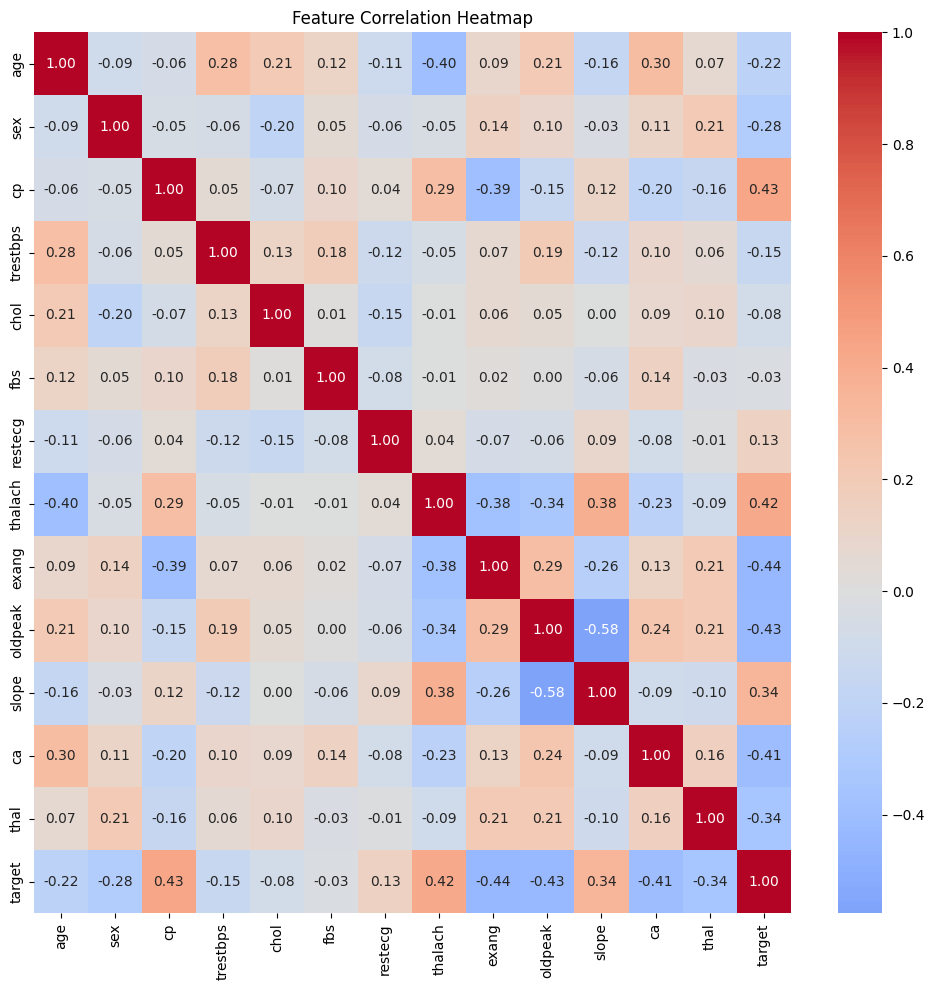

In [33]:
# COORELATION HEATMAP
# To see Which Features are related to eachother and target

plt.figure(figsize = (10, 10))
sns.heatmap(df.corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

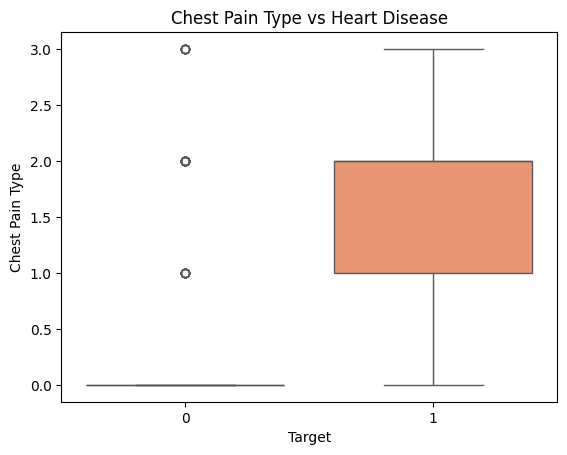

In [34]:
# CP VS HEARTDISEASE
sns.boxplot(x = 'target', y = 'cp', data = df, hue = 'target', palette = 'Set2', legend = False)
plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Target')
plt.ylabel('Chest Pain Type')
plt.show()

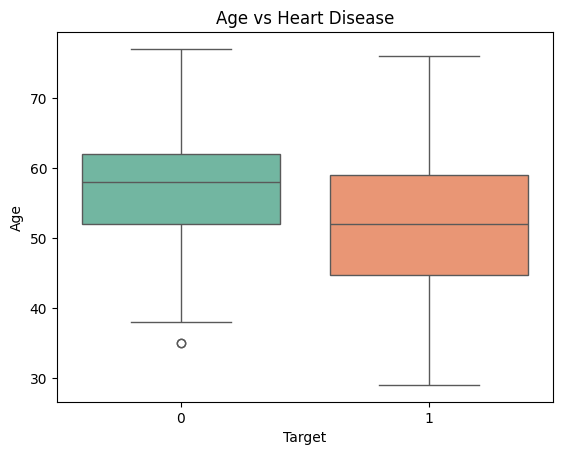

In [35]:
# AGE VS HEART DISEASE
sns.boxplot(x = 'target', y = 'age', data = df, hue = 'target', palette = 'Set2', legend = False)
plt.title('Age vs Heart Disease')
plt.xlabel('Target')
plt.ylabel('Age')
plt.show()

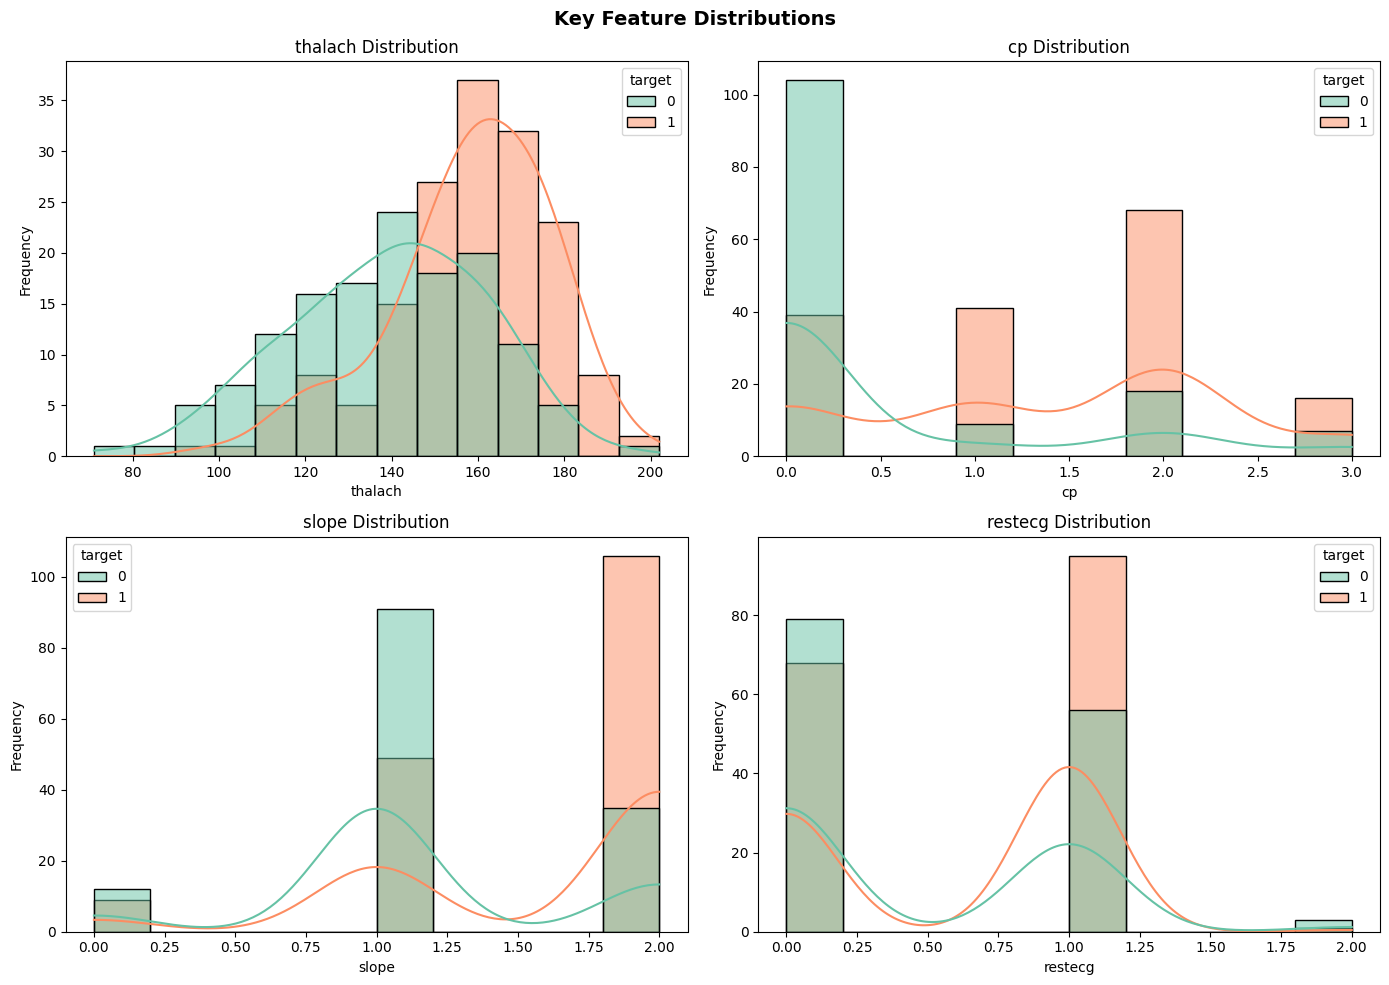

In [36]:
# KET FEATURE DISTRIBUTIONS
features = ['thalach', 'cp', 'slope', 'restecg']

fig, axes = plt.subplots(2, 2, figsize = (14, 10))

for i, feature in enumerate(features):
  ax = axes[i//2, i%2]
  sns.histplot(data = df, x = feature, hue = 'target', kde = True, ax= ax, palette = 'Set2')
  ax.set_xlabel(feature)
  ax.set_ylabel('Frequency')
  ax.set_title(f'{feature} Distribution')

plt.suptitle('Key Feature Distributions', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

In [37]:
# PREPROCESSING
# Understanding Our columns:

columns = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'Chest Pain Type',
    'trestbps': 'Resting Blood Pressure',
    'chol': 'Cholesterol',
    'fbs': 'Fasting Blood Sugar',
    'restecg': 'Resting Electrocardiographic Results',
    'thalach': 'Maximum Heart Rate Achieved',
    'exang': 'Exercise Induced Angina',
    'oldpeak': 'ST Depression Induced by Exercise',
    'slope': 'Slope of the Peak Exercise ST Segment',
    'ca': 'Number of Major Vessels',
    'thal': 'Thalassemia',
    'target': 'Heart Disease'
}

for col, desc in columns.items():
  print(f"{col:10} -> {desc}")

age        -> Age
sex        -> Sex
cp         -> Chest Pain Type
trestbps   -> Resting Blood Pressure
chol       -> Cholesterol
fbs        -> Fasting Blood Sugar
restecg    -> Resting Electrocardiographic Results
thalach    -> Maximum Heart Rate Achieved
exang      -> Exercise Induced Angina
oldpeak    -> ST Depression Induced by Exercise
slope      -> Slope of the Peak Exercise ST Segment
ca         -> Number of Major Vessels
thal       -> Thalassemia
target     -> Heart Disease


In [38]:
#Splitting Columns and encoding data

categorical_cols = ['cp', 'restecg', 'slope', 'ca', 'thal']
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
binary_col = ['sex', 'fbs', 'exang']

df_encoded = pd.get_dummies(df, columns = categorical_cols, drop_first = True)

print("Shape before encoding: ", df.shape)
print("Shape after encoding: ", df_encoded.shape)
print("\nEncoded Data: ")
df_encoded.head()

Shape before encoding:  (302, 14)
Shape after encoding:  (302, 23)

Encoded Data: 


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,target,cp_1,...,restecg_2,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,1,125,212,0,168,0,1.0,0,False,...,False,False,True,False,True,False,False,False,False,True
1,53,1,140,203,1,155,1,3.1,0,False,...,False,False,False,False,False,False,False,False,False,True
2,70,1,145,174,0,125,1,2.6,0,False,...,False,False,False,False,False,False,False,False,False,True
3,61,1,148,203,0,161,0,0.0,0,False,...,False,False,True,True,False,False,False,False,False,True
4,62,0,138,294,1,106,0,1.9,0,False,...,False,True,False,False,False,True,False,False,True,False


In [39]:
# Separating Features and Target
X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

print("Shape of Features: ", X.shape)
print("Shape of Target: ", y.shape)

Shape of Features:  (302, 22)
Shape of Target:  (302,)


In [40]:
# Train/Test split:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scaling Features after splitting
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")
print(f"\nTarget balance in train: {y_train.value_counts().to_dict()}")
print(f"Target balance in test: {y_test.value_counts().to_dict()}")
print("\nSample of Scaled Training Data: ")
display(X_train[numerical_cols].head())

Training set: 241 samples
Testing set: 61 samples

Target balance in train: {1: 131, 0: 110}
Target balance in test: {1: 33, 0: 28}

Sample of Scaled Training Data: 


,age,trestbps,chol,thalach,oldpeak
158,1.421944,-0.973041,5.882908,0.408240,0.527263
199,-0.465841,0.756507,-0.885696,-1.104705,-0.083233
479,0.422528,-0.197726,-0.588175,-0.882213,1.050546
460,1.644036,0.517949,0.118437,-0.214737,0.876119
169,-1.021072,-1.151959,-1.629499,-0.570724,-0.868157


###PHASE 4 - MODEL TRAINING

In [41]:
# Defining Models

models = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(),
    'XGBoost': XGBClassifier()
}

print("Models Defined: ")
for name in models:
  print(f" -> {name}")

Models Defined: 
 -> Logistic Regression
 -> Random Forest
 -> XGBoost


In [42]:
# Cross Validation on All Models Using StartifiedKFold
# (Splitting data in 5 folds, Train on 4, Test on 1, Rotate 5 Times)
# Evlauation Using cross_val_score

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
print(f"{'Model':<25} {'Mean AUC':>10} {'Std AUC':>10}")
print("-" * 47)

for name, model in models.items():
  scores = cross_val_score(model, X_train, y_train, cv = cv, scoring = 'roc_auc')
  print(f"{name:<25} {scores.mean():>10.4f} {scores.std():>10.4f}")

Model                       Mean AUC    Std AUC
-----------------------------------------------
Logistic Regression           0.9243     0.0358
Random Forest                 0.8844     0.0523
XGBoost                       0.8922     0.0403


In [43]:
#Training Models

trained_models = {}

for name, model in models.items():
  model.fit(X_train, y_train)
  trained_models[name] = model;
  print(f"{name} trained!")


Logistic Regression trained!
Random Forest trained!
XGBoost trained!


In [44]:
# Performance Check Of Each Model

print(f"{'Model':<25} {'Accuracy':>10} {'F1 Score':>10} {'AUC':>10}")
print("-" * 57)

test_results = {}

for name, model in trained_models.items():
  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)[:, 1]

  acc = accuracy_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_proba)

  test_results[name] = {'Accuracy': acc, 'F1 Score': f1, 'AUC': auc}
  print(f"{name:<25} {acc:>10.4f} {f1:>10.4f} {auc:>10.4f}")


Model                       Accuracy   F1 Score        AUC
---------------------------------------------------------
Logistic Regression           0.8525     0.8615     0.9026
Random Forest                 0.7869     0.8000     0.8907
XGBoost                       0.7869     0.7937     0.8528


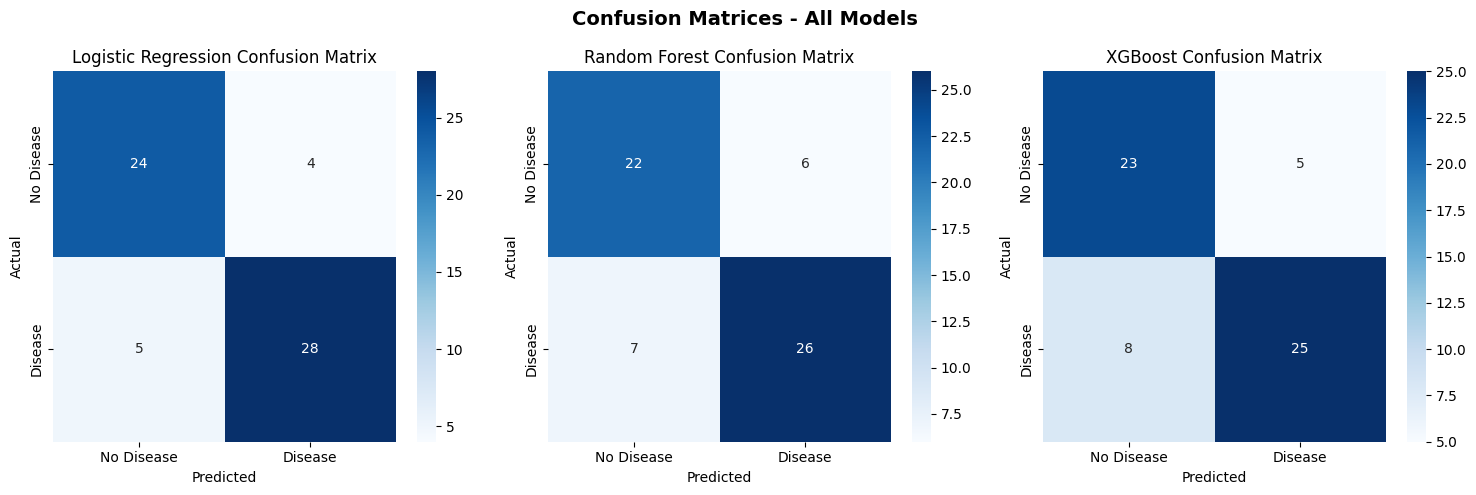

In [45]:
# Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize = (15, 5))

for ax, (name, model) in zip(axes, trained_models.items()):
  y_pred = model.predict(X_test)
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(cm, annot= True, fmt = 'd', cmap = 'Blues', ax = ax, xticklabels = ['No Disease', 'Disease'], yticklabels = ['No Disease', 'Disease'])
  ax.set_title(f'{name} Confusion Matrix')
  ax.set_xlabel('Predicted')
  ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices - All Models', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()


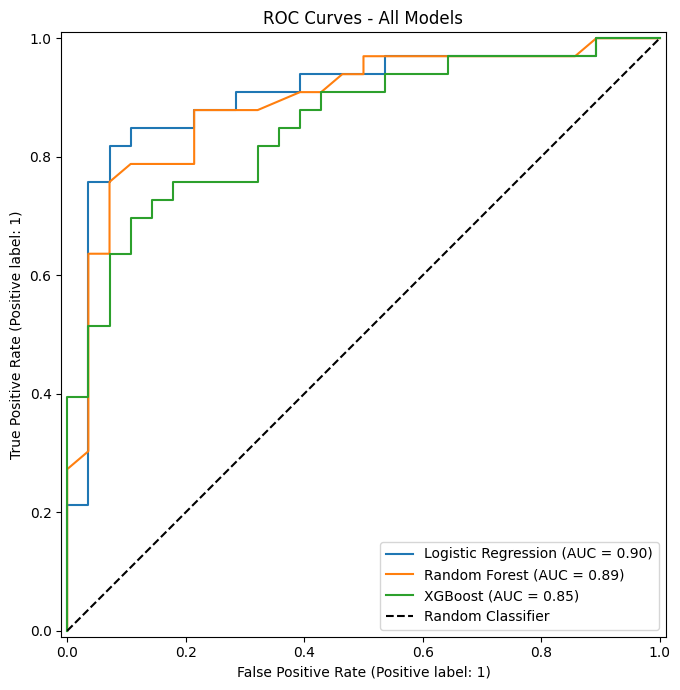

In [46]:
# ROC curves for all 3

fig, ax = plt.subplots(figsize = (10, 7))

for name, model in trained_models.items():
  RocCurveDisplay.from_estimator(model, X_test, y_test, name = name, ax = ax)

ax.plot([0,1], [0,1], 'k--', label = 'Random Classifier')
ax.set_title('ROC Curves - All Models')
ax.legend(loc = 'lower right')
plt.tight_layout()
plt.show()

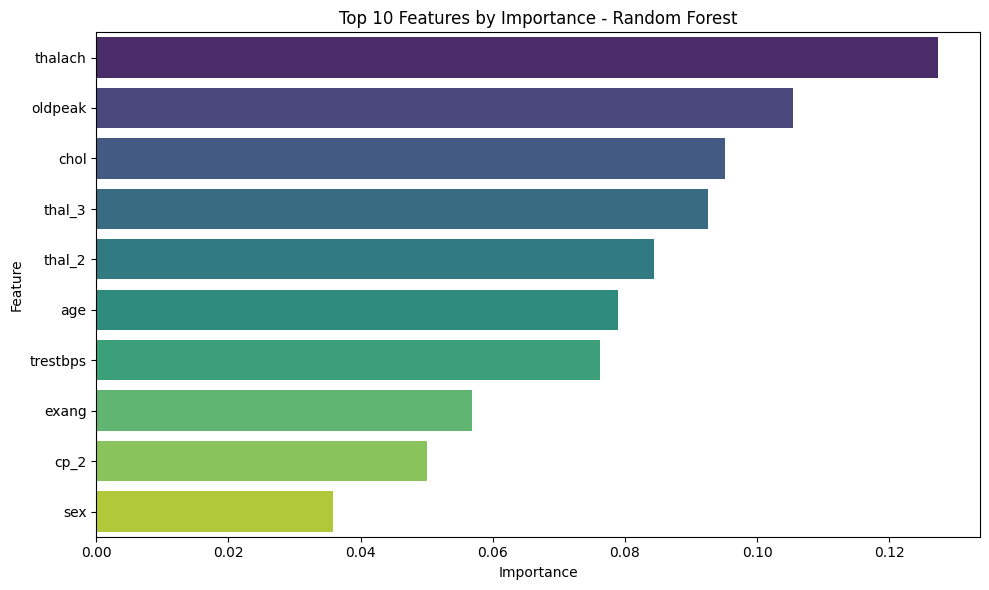

In [48]:
# Feature Importance using random Forest

importances = trained_models['Random Forest'].feature_importances_
feat_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances}).sort_values('Importance', ascending = False).head(10)

plt.figure(figsize = (10, 6))
sns.barplot(x = 'Importance', y = 'Feature', data = feat_df, palette = 'viridis', legend = False, hue = 'Feature')
plt.title('Top 10 Features by Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


# Heart Disease Prediction — Comparative ML Study

## Problem Statement
Heart disease is one of the leading causes of death globally. Early prediction using
patient clinical data can assist medical professionals in identifying high-risk individuals.
This project builds and compares three machine learning models to predict the presence
of heart disease using the UCI Heart Disease dataset.

---

## Dataset
- **Source:** UCI Machine Learning Repository / Kaggle
- **Samples:** 302 patients (after removing 723 duplicate rows from the original 1,025)
- **Features:** 13 clinical features (age, cholesterol, chest pain type, max heart rate, etc.)
- **Target:** Binary — 1 (heart disease present), 0 (absent)
- **Class Balance:** Well balanced — no resampling required

---

## Data Quality Note
The raw Kaggle version of this dataset contained 723 duplicate rows. These were identified
and removed prior to modelling. This is a common issue with public datasets and an important
preprocessing step — leaving duplicates in causes identical rows to appear in both train
and test sets, artificially inflating model performance to near-perfect scores. After
cleaning, results reflect genuine generalisation ability.

---

## Exploratory Data Analysis — Key Findings
- No missing values found across any feature
- **Thalach** (maximum heart rate achieved) showed the strongest correlation with the
  target variable — patients with heart disease tended to achieve higher max heart rates
- **Age** distribution showed younger patients slightly more represented in the disease
  class, which aligns with the thalach finding
- Cholesterol and resting blood pressure showed weaker individual correlations but
  contributed meaningfully in combination

---

## Preprocessing
- Categorical features (`cp`, `restecg`, `slope`, `ca`, `thal`) one-hot encoded to
  prevent ordinal misinterpretation by models
- Numerical features scaled using StandardScaler for Logistic Regression compatibility
- 80/20 stratified train/test split with `random_state=42` for reproducibility

---

## Models Trained
| Model | Reason for Inclusion |
|---|---|
| Logistic Regression | Baseline linear model, highly interpretable |
| Random Forest | Ensemble method, handles non-linearity, provides feature importance |
| XGBoost | Gradient boosting, typically strong on tabular data |

---

## Results

### Cross-Validation (5-Fold, AUC)
| Model | Mean AUC | Std |
|---|---|---|
| Logistic Regression | 0.9243 | 0.0358 |
| Random Forest | 0.8844 | 0.0523 |
| XGBoost | 0.8922 | 0.0403 |

### Test Set Performance
| Model | Accuracy | F1 Score | AUC |
|---|---|---|---|
| Logistic Regression | 0.8525 | 0.8615 | 0.9026 |
| Random Forest | 0.7869 | 0.8000 | 0.8907 |
| XGBoost | 0.7869 | 0.7937 | 0.8528 |

---

## Key Findings

- **Best Performing Model: Logistic Regression** — achieved the highest scores across
  all metrics (Accuracy: 85.25%, F1: 86.15%, AUC: 0.9026) and the strongest
  cross-validated AUC of 0.9243. This suggests the relationship between clinical
  features and heart disease presence is largely linear in this dataset.

- **Tree-based models underperformed relative to expectations** — Random Forest and
  XGBoost typically excel on tabular data, but on this cleaned dataset their test
  AUC (0.89 and 0.85) fell below Logistic Regression. This is likely because the
  dataset is small (~830 rows) and the signal is linear — conditions where simpler
  models generalise better.

- **Most Important Features (Random Forest):** Thalach (max heart rate), Oldpeak
  (ST depression), and Cholesterol were the top predictors — consistent with the
  EDA findings and medically plausible.

- **Duplicate Detection:** Initial runs produced suspiciously perfect scores
  (100% accuracy). Investigation revealed 723 duplicate rows in the raw dataset.
  Removing these brought results to realistic levels, demonstrating the importance
  of thorough data quality checks before modelling.

- **Cross-Validation Stability:** Standard deviations across all models were
  acceptably low (≤0.05), indicating stable performance across different data splits.

---

## Conclusion
This project demonstrated that clinical features can predict heart disease with strong
accuracy. Contrary to typical expectations, Logistic Regression outperformed ensemble
methods on this dataset — a finding that highlights the importance of model selection
based on data characteristics rather than model complexity. A key lesson from this
project was identifying and resolving duplicate-row contamination that initially produced
misleading perfect scores. Future work could explore hyperparameter tuning, SHAP values
for clinical explainability, and validation on a larger independent dataset.

---

## Tools & Libraries
Python, pandas, NumPy, scikit-learn, XGBoost, matplotlib, seaborn, Google Colab